In [1]:
import torch
import pysiglib.torch_api as pysiglib
import pandas as pd
import numpy as np
import time
import gc

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
df = pd.read_csv('datasets/heston.csv')

In [4]:
paths = np.array(df['history_S'].str.split(',').tolist(), dtype=float)
paths = torch.from_numpy(paths).float().unsqueeze(2)

In [5]:
paths.shape

torch.Size([10000, 151, 1])

In [6]:
# Plot time taken and memory usage for different degrees of the signature computed on the GPU
times = []
mems = []

# Initialise pysiglib cache 
sig = pysiglib.sig(paths.to(device), 1, time_aug=True, lead_lag=True)

for degree in range(1, 11):
    start_time = time.time()
    sig = pysiglib.sig(paths.to(device), degree, time_aug=True, lead_lag=True)
    end_time = time.time()
    print(f"Degree: {degree}, Time taken: {end_time - start_time:.4f} seconds, Memory usage: {torch.cuda.memory_allocated(device) / (1024 ** 2):.2f} MB")
    times.append(end_time - start_time)
    mems.append(torch.cuda.memory_allocated(device) / (1024 ** 2))
    del sig  # Free up memory for the next iteration
    gc.collect()  # Run garbage collection to free up memory
    torch.cuda.empty_cache()  # Clear the GPU cache to free up memory

Degree: 1, Time taken: 0.0019 seconds, Memory usage: 0.11 MB
Degree: 2, Time taken: 0.0022 seconds, Memory usage: 0.46 MB
Degree: 3, Time taken: 0.0034 seconds, Memory usage: 1.49 MB
Degree: 4, Time taken: 0.0050 seconds, Memory usage: 4.58 MB
Degree: 5, Time taken: 0.0106 seconds, Memory usage: 14.24 MB
Degree: 6, Time taken: 0.0340 seconds, Memory usage: 42.00 MB
Degree: 7, Time taken: 0.1204 seconds, Memory usage: 126.00 MB
Degree: 8, Time taken: 0.3796 seconds, Memory usage: 376.00 MB
Degree: 9, Time taken: 1.4232 seconds, Memory usage: 1126.21 MB
Degree: 10, Time taken: 5.1039 seconds, Memory usage: 3378.75 MB


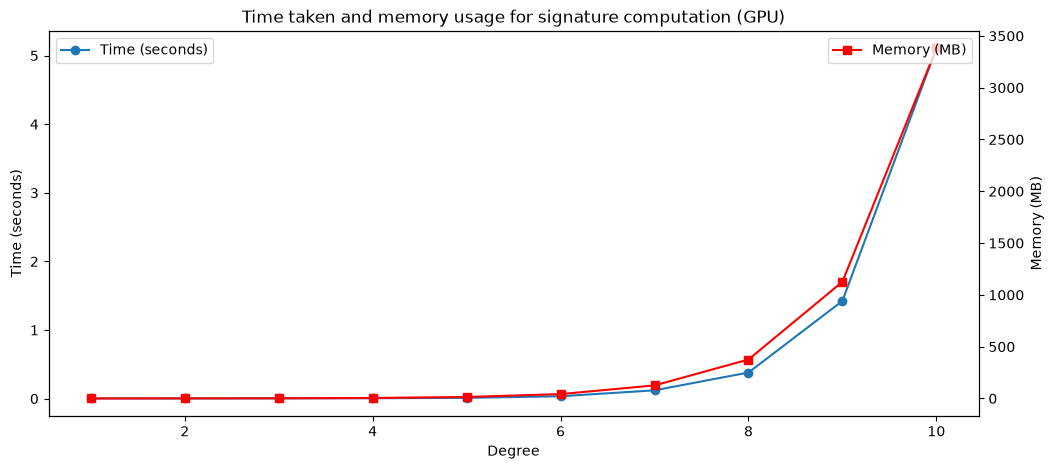

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

# Plot times and memory usage as a function of degree on the same plot with two y-axes
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(range(1, 11), times, marker='o', label='Time (seconds)')
ax1.set_xlabel('Degree')
ax1.set_ylabel('Time (seconds)')
ax1.tick_params(axis='y')

ax2 = ax1.twinx()
ax2.plot(range(1, 11), mems, marker='s', label='Memory (MB)', color='red')
ax2.set_ylabel('Memory (MB)')
ax2.tick_params(axis='y')

ax1.legend(loc='upper left')
ax2.legend(loc='upper left')
plt.title('Time taken and memory usage for signature computation (GPU)')
plt.show()

In [8]:
# Time taken on CPU
times_cpu = []
device = 'cpu'
for degree in range(1, 10):
    start_time = time.time()
    sig_cpu = pysiglib.sig(paths, degree, time_aug=True, lead_lag=True)
    end_time = time.time()
    print(f"Degree: {degree}, Time taken: {end_time - start_time:.4f} seconds")
    times_cpu.append(end_time - start_time)
    del sig_cpu  # Free up memory for the next iteration
    gc.collect()  # Run garbage collection to free up memory

/home/gaurav/.venvs/sig_nsde/lib/python3.12/site-packages/torch/autograd/function.py:625: UserWarning: Detected a non-contiguous or view-based array. Such arrays will be cloned to ensure safe access. To avoid this overhead, pass arrays that are both contiguous and own their data. This warning will only appear once per session.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Degree: 1, Time taken: 0.0022 seconds
Degree: 2, Time taken: 0.0453 seconds
Degree: 3, Time taken: 0.0736 seconds
Degree: 4, Time taken: 0.1553 seconds
Degree: 5, Time taken: 0.3639 seconds
Degree: 6, Time taken: 0.9870 seconds
Degree: 7, Time taken: 2.6323 seconds
Degree: 8, Time taken: 7.6743 seconds
Degree: 9, Time taken: 24.5579 seconds


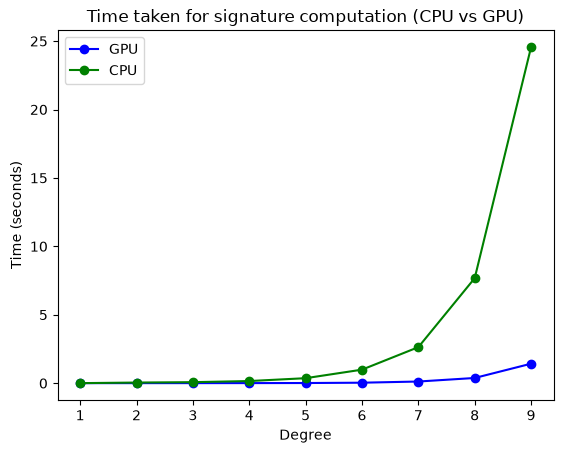

In [9]:
# Time taken on CPU against GPU
times_gpu = times[:9]
plt.plot(range(1, 10), times_gpu, marker='o', label='GPU', color='blue')
plt.plot(range(1, 10), times_cpu, marker='o', label='CPU', color='green')
plt.xlabel('Degree')
plt.ylabel('Time (seconds)')
plt.title('Time taken for signature computation (CPU vs GPU)')
plt.legend()
plt.show()